In [5]:
from __future__ import annotations
import os
import sys
from pathlib import Path
import pandas as pd
import matplotlib.pyplot as plt
from rich import print as rprint

In [6]:


# Notebook is inside src/data → go up TWO levels to reach project root
# ROOT = Path.cwd().parents[1]

# if str(ROOT) not in sys.path:
#     sys.path.insert(0, str(ROOT))

# print("Project root:", ROOT)


In [7]:
from data.fetch_databento import run_fetch
from data.etl_to_catalog import run_etl
from data.csv_extract import run_csv_extract
from data.inspect_catalog import inspect_catalog_summary

## CONFIG

In [8]:
dataset   = "GLBX.MDP3"
symbols   = ["ES.n.0"]
stype_in  = "continuous"
start     = "2023-12-06T14:30:00Z"
end       = "2023-12-06T15:00:00Z"
schemas   = ["ohlcv-1m", "tbbo", "trades"]
catalog_path = "catalog"
out_dir      = "interim"

if not os.getenv("DATABENTO_API_KEY"):
    rprint("[yellow]Warning[/yellow]: DATABENTO_API_KEY not in env; .env will be used if present.")


In [4]:
# 1) Fetch
rprint("[bold cyan]1) Fetch raw DBN files[/bold cyan]")
entries = []
for schema in schemas:
    e = run_fetch(dataset, symbols, stype_in, schema, start, end)
    rprint({"schema": schema, "path": e["path"], "bytes": e["bytes"]})
    entries.append(e)
    
paths = [e["path"] for e in entries]


1) Fetch raw DBN files

Fetching GLBX.MDP3 ['ES.n.0'] ohlcv-1m 2023-12-06T14:30:00Z→2023-12-06T15:00:00Z

Saved 
raw\GLBX.MDP3__ES.n.0__continuous__ohlcv-1m__20231206T143000Z__20231206T150000Z__40fbb4d94cca3327325ece073a328b97a7
3e247b77f6f59124fef44046940183.dbn.zst (704 bytes)

Manifest updated at raw\manifest.json

{
    'schema': 'ohlcv-1m',
    'path': 
'raw\\GLBX.MDP3__ES.n.0__continuous__ohlcv-1m__20231206T143000Z__20231206T150000Z__40fbb4d94cca3327325ece073a328b97
a73e247b77f6f59124fef44046940183.dbn.zst',
    'bytes': 704
}

...

{
    'schema': 'tbbo',
    'path': 
'raw\\GLBX.MDP3__ES.n.0__continuous__tbbo__20231206T143000Z__20231206T150000Z__f55ce0d8f3a992376bbd69cb2f6fbea36909
3fee76d314bd01e739bb484ca21e.dbn.zst',
    'bytes': 884184
}

Fetching GLBX.MDP3 ['ES.n.0'] trades 2023-12-06T14:30:00Z→2023-12-06T15:00:00Z

Saved 
raw\GLBX.MDP3__ES.n.0__continuous__trades__20231206T143000Z__20231206T150000Z__8c54a4e56dccde3934db6607eec409017f33
820dfbe858cb12d0b4e8fe8cc68e.dbn.zst (616,979 bytes)

Manifest updated at raw\manifest.json

{
    'schema': 'trades',
    'path': 
'raw\\GLBX.MDP3__ES.n.0__continuous__trades__20231206T143000Z__20231206T150000Z__8c54a4e56dccde3934db6607eec409017f
33820dfbe858cb12d0b4e8fe8cc68e.dbn.zst',
    'bytes': 616979
}

In [9]:
rprint("\n[bold cyan]2) Build Parquet catalog[/bold cyan]")
manifest = run_etl(instrument_id=symbols[0],
                   catalog_path=catalog_path,
                   overwrite=True,
                   paths=paths)
rprint(manifest)

2) Build Parquet catalog

Wrote instrument: ES.n.0

Loading 
GLBX.MDP3__ES.n.0__continuous__ohlcv-1m__20231206T143000Z__20231206T150000Z__40fbb4d94cca3327325ece073a328b97a73e24
7b77f6f59124fef44046940183.dbn.zst

Loading 
GLBX.MDP3__ES.n.0__continuous__tbbo__20231206T143000Z__20231206T150000Z__f55ce0d8f3a992376bbd69cb2f6fbea369093fee76
d314bd01e739bb484ca21e.dbn.zst

Loading 
GLBX.MDP3__ES.n.0__continuous__trades__20231206T143000Z__20231206T150000Z__8c54a4e56dccde3934db6607eec409017f33820d
fbe858cb12d0b4e8fe8cc68e.dbn.zst

Catalog ready at catalog

{
    'instrument_id': 'ES.n.0',
    'classes': {'Bar': 30, 'QuoteTick': 44938, 'TradeTick': 44938},
    'time_bounds_ns': {
        'Bar': {'min': 1701873060000000000, 'max': 1701874800000000000},
        'QuoteTick': {'min': 1701873000000779444, 'max': 1701874799936268321},
        'TradeTick': {'min': 1701873000000779444, 'max': 1701874799936268321}
    },
    'catalog_path': 'catalog'
}

{
    'instrument_id': 'ES.n.0',
    'classes': {'Bar': 30, 'QuoteTick': 44938, 'TradeTick': 44938},
    'time_bounds_ns': {
        'Bar': {'min': 1701873060000000000, 'max': 1701874800000000000},
        'QuoteTick': {'min': 1701873000000779444, 'max': 1701874799936268321},
        'TradeTick': {'min': 1701873000000779444, 'max': 1701874799936268321}
    },
    'catalog_path': 'catalog'
}

In [10]:
# 3) Inspect
rprint("\n[bold cyan]3) Inspect catalog summary[/bold cyan]")
summary = inspect_catalog_summary(catalog_path)
rprint(summary)

3) Inspect catalog summary

{
    'manifest_path': 'catalog\\manifest.json',
    'classes': {'Bar': 30, 'QuoteTick': 44938, 'TradeTick': 44938},
    'time_bounds_ns': {
        'Bar': {'min': 1701873060000000000, 'max': 1701874800000000000},
        'QuoteTick': {'min': 1701873000000779444, 'max': 1701874799936268321},
        'TradeTick': {'min': 1701873000000779444, 'max': 1701874799936268321}
    }
}

In [11]:
rprint("\n[bold cyan]4) Export CSVs[/bold cyan]")
csv_paths = run_csv_extract(source="catalog",
                            instrument_id=symbols[0],
                            catalog_path=catalog_path,
                            out_dir=out_dir)
rprint(csv_paths)

4) Export CSVs

Wrote interim\trades.csv (44,938 rows)

Wrote interim\quotes.csv (44,938 rows)

Wrote interim\bars_for_viz.csv (30 rows)

{'trades': 'interim\\trades.csv', 'quotes': 'interim\\quotes.csv', 'bars': 'interim\\bars_for_viz.csv'}

In [12]:
# 5) Pandas previews
out = Path(out_dir)
bars_p   = out / "bars_for_viz.csv"
quotes_p = out / "quotes.csv"
trades_p = out / "trades.csv"

if bars_p.exists():
    bars = pd.read_csv(bars_p)
    bars["t_start"] = pd.to_datetime(bars["ts_start_ns"], unit="ns", utc=True)
    rprint("[green]bars_for_viz.csv[/green]")
    rprint(bars.head(3))
else:
    rprint("[yellow]No bars_for_viz.csv[/yellow]")

if quotes_p.exists():
    quotes = pd.read_csv(quotes_p)
    quotes["t_event"] = pd.to_datetime(quotes["ts_event_ns"], unit="ns", utc=True)
    rprint("[green]quotes.csv[/green]")
    rprint(quotes.head(3))
else:
    rprint("[yellow]No quotes.csv[/yellow]")

if trades_p.exists():
    trades = pd.read_csv(trades_p)
    trades["t_event"] = pd.to_datetime(trades["ts_event_ns"], unit="ns", utc=True)
    rprint("[green]trades.csv[/green]")
    rprint(trades.head(3))
else:
    rprint("[yellow]No trades.csv[/yellow]")


bars_for_viz.csv

ts_start_ns            ts_end_ns instrument_id  symbol     open  \
0  1701873060000000000  1701873060000000000        ES.n.0     NaN  4597.25   
1  1701873120000000000  1701873120000000000        ES.n.0     NaN  4595.75   
2  1701873180000000000  1701873180000000000        ES.n.0     NaN  4596.25   

      high      low    close   volume  bar_span_s  dataset  \
0  4597.50  4594.50  4595.50  13341.0           0      NaN   
1  4597.25  4594.75  4596.25   8853.0           0      NaN   
2  4597.50  4594.50  4595.00   6408.0           0      NaN   

                    t_start  
0 2023-12-06 14:31:00+00:00  
1 2023-12-06 14:32:00+00:00  
2 2023-12-06 14:33:00+00:00

quotes.csv

ts_event_ns           ts_recv_ns instrument_id  symbol  bid_price  \
0  1701873000000779444  1701873000000779444        ES.n.0     NaN    4597.25   
1  1701873000000833822  1701873000000833822        ES.n.0     NaN    4597.25   
2  1701873000001594242  1701873000001594242        ES.n.0     NaN    4597.25   

   bid_size  ask_price  ask_size          source  spread       mid  \
0      88.0     4597.5      78.0  catalog_or_dbn    0.25  4597.375   
1      87.0     4597.5      78.0  catalog_or_dbn    0.25  4597.375   
2      88.0     4597.5      96.0  catalog_or_dbn    0.25  4597.375   

                              t_event  
0 2023-12-06 14:30:00.000779444+00:00  
1 2023-12-06 14:30:00.000833822+00:00  
2 2023-12-06 14:30:00.001594242+00:00

trades.csv

ts_event_ns           ts_recv_ns instrument_id  symbol    price  \
0  1701873000000779444  1701873000000779444        ES.n.0     NaN  4597.25   
1  1701873000000833822  1701873000000833822        ES.n.0     NaN  4597.25   
2  1701873000001594242  1701873000001594242        ES.n.0     NaN  4597.50   

   size  dataset                             t_event  
0   1.0      NaN 2023-12-06 14:30:00.000779444+00:00  
1   4.0      NaN 2023-12-06 14:30:00.000833822+00:00  
2   8.0      NaN 2023-12-06 14:30:00.001594242+00:00

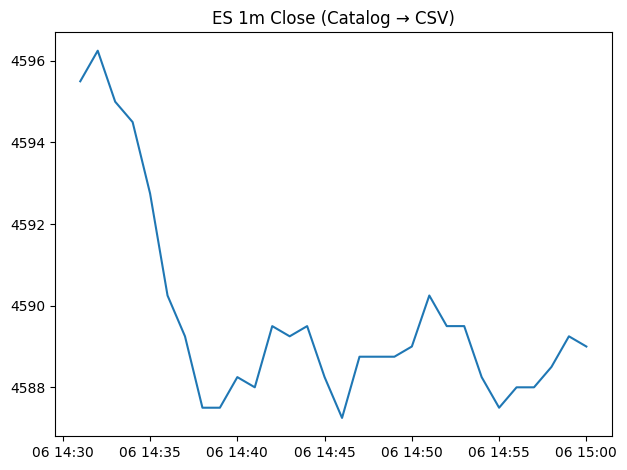

In [13]:
# 6) Simple plot (optional)
if bars_p.exists():
    bars_sorted = bars.sort_values("t_start")
    plt.plot(bars_sorted["t_start"], bars_sorted["close"])
    plt.title("ES 1m Close (Catalog → CSV)")
    plt.tight_layout()
    try:
        plt.show()
    except Exception:
        out_img = out / "bars_close.png"
        plt.savefig(out_img)
        rprint(f"[green]Saved plot[/green]: {out_img}")